# TIC Kids Online Brasil (2015–2025): três medidas de mediação parental

**Versão 2 — documentação ampliada e exploração gráfica antes da inferência.** Esta análise organiza a evidência em três medidas distintas: (1) percepção da criança sobre quanto os responsáveis sabem do que ela faz na Internet (U1); (2) conversa sobre a vida online autorrelatada pelo responsável; e (3) conversa sobre a vida online percebida pela criança.

As ondas são cortes transversais anuais, não um painel das mesmas famílias. O pareamento dentro de cada ano usa o responsável e a criança da mesma linha/domicílio quando ambas as respostas estão disponíveis. Uma diferença entre informantes não determina qual relato está correto.

**Harmonização da conversa:** itens binários “sim/não” das ondas antigas e escalas de frequência de 2024/2025 são convertidos para **qualquer conversa versus nunca**. Nas escalas 1–5, códigos 1–4 significam alguma conversa e 5 significa “Nunca”. É uma harmonização interpretável, mas descarta intensidade/frequência. U1 permanece uma variável ordinal separada e não é tratada como sinônimo de conversa.

## Mapa dos testes por seção

Os testes são bilaterais, com α = 0,05. A descrição gráfica precede cada bloco inferencial. “Ano” é tratado como preditor linear em cortes transversais independentes; não representa mudança das mesmas famílias.

| Seção analítica | Teste | Hipótese nula (H₀) | Hipótese alternativa (H₁) | Escopo e medida de efeito |
|---|---|---|---|---|
| **2. U1 — conhecimento parental percebido** | Logístico ordinal de chances proporcionais | β do ano = 0; a distribuição ordinal de U1 não tem tendência temporal | β do ano ≠ 0; a distribuição muda ao longo dos anos | OR anual para deslocamento a categorias mais altas/mais baixas; IC95%. Pressupõe chances proporcionais. |
| **2. U1 — sensibilidades** | Dois GLMs logísticos binomiais | OR anual = 1 para cada limiar (“Muito”; “Muito/Mais ou menos”) | OR anual ≠ 1 | OR/ano e IC95%; ajuste Holm entre os dois limiares. |
| **3. Autorrelato do responsável** | GLM logístico binomial | β do ano = 0; chances de relatar alguma conversa são constantes | β do ano ≠ 0; há tendência temporal | OR/ano e IC95% HC3; ondas disponíveis para o item parental. |
| **4. Percepção infantil de conversa** | GLM logístico binomial | β do ano = 0; chances de perceber alguma conversa são constantes | β do ano ≠ 0; há tendência temporal | OR/ano e IC95% HC3; ajuste Holm junto ao teste de tendência parental. |
| **4. Pareamento anual** | McNemar binomial exato | Entre as díades, as discordâncias “responsável sim/criança não” e “responsável não/criança sim” têm a mesma probabilidade; margens iguais | As probabilidades de discordância direcional diferem; margens não iguais | Diferença pareada com IC95% bootstrap; ajuste Holm entre as seis ondas pareáveis. κ de Cohen e AC1 de Gwet são medidas de concordância com ICs, não testes de hipótese neste notebook. |
| **4. Sensibilidade ordinal 2024** | Wilcoxon de postos sinalizados | Sob simetria, a pseudomediana das diferenças ordinais pareadas é zero | A pseudomediana difere de zero | W, z aproximado, p, correlação bisserial de postos e IC95% bootstrap. É análise específica de 2024, não comparável diretamente às ondas binárias. |
| **4. Gap** | Logístico para discordância e OLS para gap líquido | Inclinação anual = 0 em cada estimando: chance de discordar ou diferença líquida média | Inclinação anual ≠ 0 | OR/ano da discordância; β anual do gap líquido; IC95% HC3. Holm ajusta os dois testes do gap. |

McNemar avalia assimetria das discordâncias pareadas; κ/AC1 quantificam concordância. Nenhum desses resultados, isoladamente, define qual informante está correto. ICs e testes não ajustados ao desenho amostral complexo devem ser lidos como inferência clássica.

## 1. Configuração, inventário e harmonização documental

Nesta seção identificamos os arquivos, calculamos hashes, lemos dos ODS os rótulos e categorias dos itens-chave e conferimos a presença nos CSVs. O item U6_G muda de significado em ondas antigas (conversa com professor) para conversa com pais em 2024/2025; o mapeamento segue o dicionário de cada ano, sem inferir equivalência pelo nome isolado. 2020 é ausência de coleta, não uma observação faltante da série.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET
import re, hashlib, platform
import numpy as np
import pandas as pd
import scipy
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
from statsmodels.miscmodels.ordinal_model import OrderedModel
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED=2026
B_BOOT=1000
ANOS=list(range(2015,2026))
SENTINELAS={88,97,98,99}
PALETA={"responsavel":"#087E8B","crianca":"#E08E45","conhecimento":"#4D90A6","gap":"#665191","neutro":"#6C7A89"}
RAIZ=Path.cwd()
while RAIZ!=RAIZ.parent and not (RAIZ/"dados_anuais").is_dir(): RAIZ=RAIZ.parent
PASTA_DADOS=RAIZ/"dados_anuais"; PASTA_DIC=RAIZ/"dicionarios_anuais"
assert PASTA_DADOS.is_dir() and PASTA_DIC.is_dir(), "Confira a pasta de trabalho e as pastas de dados/dicionários."
print(f"Raiz: {RAIZ} | Python {platform.python_version()} | pandas {pd.__version__} | SciPy {scipy.__version__}")

NS={"table":"urn:oasis:names:tc:opendocument:xmlns:table:1.0","text":"urn:oasis:names:tc:opendocument:xmlns:text:1.0"}
def ano_arquivo(p):
    m=re.search(r"(?:19|20)\d{2}",p.name); return int(m.group()) if m else None
def texto_celula(c):
    return " ".join("".join(p.itertext()) for p in c.findall(".//text:p",NS)).strip()
def ler_ods(p):
    saida=[]
    with ZipFile(p) as z: raiz_xml=ET.fromstring(z.read("content.xml"))
    for aba in raiz_xml.findall(".//table:table",NS):
        for linha in aba.findall("table:table-row",NS):
            vals=[]
            for cel in list(linha):
                if cel.tag.split("}")[-1] in ("table-cell","covered-table-cell"):
                    v=texto_celula(cel); rep=int(cel.get("{%s}number-columns-repeated"%NS["table"],"1"))
                    vals.extend([v]*min(rep,30))
            if len(vals)>=3 and vals[1].strip():
                saida.append({"variável":vals[1].strip(),"descrição":vals[2].strip(),
                    "tipo":vals[3].strip() if len(vals)>3 else "","códigos":vals[4].strip() if len(vals)>4 else ""})
    return pd.DataFrame(saida)

ARQS_CSV={ano_arquivo(p):p for p in PASTA_DADOS.rglob("*.csv") if ano_arquivo(p)}
ARQS_ODS={ano_arquivo(p):p for p in PASTA_DIC.rglob("*.ods") if ano_arquivo(p)}
CABECALHOS={a:list(pd.read_csv(p,sep=";",nrows=0,encoding="utf-8-sig").columns) for a,p in ARQS_CSV.items()}
DICIONARIOS={a:ler_ods(p) for a,p in ARQS_ODS.items()}
manifesto=pd.DataFrame([{"tipo":"microdados","ano":ano_arquivo(p),"arquivo":str(p.relative_to(RAIZ)),"MB":round(p.stat().st_size/1e6,2),"SHA-256":hashlib.sha256(p.read_bytes()).hexdigest()} for p in sorted(PASTA_DADOS.rglob("*")) if p.is_file()]+
 [{"tipo":"dicionário","ano":ano_arquivo(p),"arquivo":str(p.relative_to(RAIZ)),"MB":round(p.stat().st_size/1e6,2),"SHA-256":hashlib.sha256(p.read_bytes()).hexdigest()} for p in sorted(PASTA_DIC.rglob("*.ods"))])
display(manifesto)
print("Ondas com microdados:",sorted(ARQS_CSV),"| sem microdados:",sorted(set(ANOS)-set(ARQS_CSV)))
auditoria_pesos=pd.DataFrame([{"ano":a,"PESO disponível":any(c.upper()=="PESO" for c in cols),"réplicas repN":sum(bool(re.fullmatch(r"rep\d+",c,re.I)) for c in cols)} for a,cols in CABECALHOS.items()]).sort_values("ano")
display(auditoria_pesos)

Raiz: /home/ymws/Documentos/mestrado/estatistica/internet | Python 3.10.20 | pandas 2.3.3 | SciPy 1.15.3


,tipo,ano,arquivo,MB,SHA-256
0,microdados,2015,dados_anuais/tic_kids_online_brasil_2015_crian...,2.75,5eaae0d9e9a28627f3c54e12267615cb0e80ae4047171d...
1,microdados,2016,dados_anuais/tic_kids_online_brasil_2016_crian...,2.67,eef97695ac4dff1b00eff7dd280780c0373733c988d517...
2,microdados,2017,dados_anuais/tic_kids_online_brasil_2017_crian...,2.21,a75fad3ac331e0695e880029111647dddfe3ede66f5506...
3,microdados,2018,dados_anuais/tic_kids_online_brasil_2018_crian...,2.61,c19e8c9e8415b9083417e466ab08e56990e92eecb21fbf...
4,microdados,2019,dados_anuais/tic_kids_online_brasil_2019_crian...,2.18,83a346778c3c4f44293ae7018bbf335a9caa693ae69a88...
5,microdados,2021,dados_anuais/tic_kids_online_brasil_2021_base_...,2.58,ee38d273f30171efd64c54972afd64afb1e257715fe385...
6,microdados,2022,dados_anuais/tic_kids_online_brasil_2022_base_...,2.91,0e577bd3da5feea0e964702a607e7e7c2757fecf1d24de...
7,microdados,2023,dados_anuais/tic_kids_online_brasil_2023_base_...,3.05,0c121b55cbd90d16a81944c27dbb46c7eebe3bcb428213...
8,microdados,2024,dados_anuais/tic_kids_online_brasil_2024_base_...,8.35,d2d8354704112fa76d4ec1300ee0feaac33e40bfa295ba...
9,microdados,2025,dados_anuais/tic_kids_online_brasil_2025_base_...,8.80,dd584e11930e6316850912a6c8d259bb8ba31b5b4677eb...


Ondas com microdados: [2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025] | sem microdados: [2020]


,ano,PESO disponível,réplicas repN
6,2015,True,0
0,2016,True,0
4,2017,True,0
8,2018,True,0
1,2019,True,0
9,2021,True,0
2,2022,True,200
7,2023,True,200
5,2024,True,200
3,2025,True,200


### 1.1 Dicionário interanual e regras operacionais

U1 é descrita como a avaliação da criança sobre quanto os responsáveis sabem de suas atividades na Internet: 1 = “Muito”, 2 = “Mais ou menos”, 3 = “Nada”; 97/98/99 são não resposta/não se aplica.

Para a conversa, E5_G (responsável) e U4_G (criança) são itens binários nas ondas 2015–2017, 2019 e 2022. Em 2024, E9_G e U6_G usam frequência 1–5. Os arquivos locais não contêm o autorrelato parental nos anos 2018, 2021, 2023 e 2025; nesses anos não há pareamento, embora a percepção da criança esteja disponível. Códigos U6_G de ondas antigas referentes a professor não são usados.

In [2]:
FOCO={"U1","E5_G","U4_G","E9_G","U6_G"}
linhas_dic=[]
for ano in ANOS:
    dic=DICIONARIOS.get(ano,pd.DataFrame(columns=["variável","descrição","códigos"]))
    colunas={c.upper():c for c in CABECALHOS.get(ano,[])}
    for var in sorted(FOCO):
        sub=dic[dic["variável"].str.upper()==var] if len(dic) else dic
        if len(sub):
            for _,r in sub.iterrows(): linhas_dic.append({"ano":ano,"variável":r["variável"],"presente no CSV":var in colunas,"descrição":r["descrição"],"códigos":r["códigos"]})
dicionario_interanual=pd.DataFrame(linhas_dic)
display(dicionario_interanual)

MAPA_CONVERSA={2015:("E5_G","U4_G"),2016:("E5_G","U4_G"),2017:("E5_G","U4_G"),
 2018:(None,"U4_G"),2019:("E5_G","U4_G"),2021:(None,"U4_G"),
 2022:("E5_G","U4_G"),2023:(None,"U4_G"),2024:("E9_G","U6_G"),2025:(None,"U6_G")}
MAPA_U1={a:"U1" for a in [2015,2016,2017,2018,2019,2021,2022,2023,2024,2025]}
print("Ondas pareáveis, pela presença dos dois itens:",[a for a,(p,c) in MAPA_CONVERSA.items() if p and c and p.upper() in [x.upper() for x in CABECALHOS.get(a,[])] and c.upper() in [x.upper() for x in CABECALHOS.get(a,[])]])

,ano,variável,presente no CSV,descrição,códigos
0,2015,E5_G,True,"Pensando na criança/adolescente, o responsável...","0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
1,2015,U1,True,a criança/adolescente acha que seus pais ou re...,"1 = ""Muito"" 2 = ""Mais ou menos"" 3 = ""Nada"" 97 ..."
2,2015,U4_G,True,O(s) pai(s) ou responsáveis conversa(m) com a ...,"0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
3,2015,U6_G,True,"Algum professor na escola, conversa com a cria...","0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
4,2016,E5_G,True,"Pensando na criança/adolescente, o responsável...","0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
5,2016,U1,True,A criança/adolescente acha que seus pais ou re...,"1 = ""Muito"" 2 = ""Mais ou menos"" 3 = ""Nada"" 97 ..."
6,2016,U4_G,True,O(s) pai(s) ou responsáveis conversa(m) com a ...,"0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
7,2016,U6_G,True,Algum professor na escola conversa com a crian...,"0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
8,2017,E5_G,True,"Pensando na criança/adolescente, o responsável...","0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
9,2017,U1,True,A criança/adolescente acha que seus pais ou re...,"1 = ""Muito"" 2 = ""Mais ou menos"" 3 = ""Nada"" 97 ..."


Ondas pareáveis, pela presença dos dois itens: [2015, 2016, 2017, 2019, 2022, 2024]


### 1.2 Preparação das ondas e auditoria dos pares

A leitura mantém uma observação por domicílio, preserva o peso e recodifica sentinelas como ausentes. Para os itens binários, 0/1 significam não/sim. Para E9_G/U6_G, a regra é qualquer frequência (1–4) versus nunca (5). U1 conserva suas três categorias ordenadas. Antes de qualquer teste pareado, verificamos se o identificador domiciliar é único.

In [3]:
def ler_onda(ano):
    p=ARQS_CSV[ano]; cols=CABECALHOS[ano]; nomes={c.upper():c for c in cols}
    var_resp,var_cri=MAPA_CONVERSA.get(ano,(None,None))
    solicitados={"ID_DOMICILIO":"ID_DOMICILIO","resp_raw":var_resp,"cri_raw":var_cri,"U1_raw":MAPA_U1.get(ano)}
    encontrados={k:nomes.get(v.upper()) for k,v in solicitados.items() if v}
    uso=list(dict.fromkeys([v for v in encontrados.values() if v]+([nomes["PESO"]] if "PESO" in nomes else [])))
    d=pd.read_csv(p,sep=";",decimal=",",usecols=uso,encoding="utf-8-sig",low_memory=False)
    d=d.rename(columns={orig:novo for novo,orig in encontrados.items()})
    if "PESO" in nomes:d=d.rename(columns={nomes["PESO"]:"peso"})
    if "peso" not in d:d["peso"]=1.0
    for c in ["resp_raw","cri_raw","U1_raw","peso"]:
        if c not in d:d[c]=np.nan
        d[c]=pd.to_numeric(d[c],errors="coerce")
    d["ano"]=ano
    for c in ["resp_raw","cri_raw","U1_raw"]:d.loc[d[c].isin(SENTINELAS),c]=np.nan
    d.loc[~d.U1_raw.isin([1,2,3]),"U1_raw"]=np.nan
    if var_resp and var_resp.upper()=="E5_G": d["responsavel_conversa"]=d.resp_raw.where(d.resp_raw.isin([0,1]))
    elif var_resp: d["responsavel_conversa"]=np.where(d.resp_raw.isin([1,2,3,4]),1,np.where(d.resp_raw.eq(5),0,np.nan))
    else:d["responsavel_conversa"]=np.nan
    if var_cri and var_cri.upper()=="U4_G": d["crianca_conversa"]=d.cri_raw.where(d.cri_raw.isin([0,1]))
    elif var_cri: d["crianca_conversa"]=np.where(d.cri_raw.isin([1,2,3,4]),1,np.where(d.cri_raw.eq(5),0,np.nan))
    else:d["crianca_conversa"]=np.nan
    d["conhecimento_ord"]=(4-d.U1_raw).where(d.U1_raw.notna()) # 1=nada, 2=mais ou menos, 3=muito
    d["gap"]=d.responsavel_conversa-d.crianca_conversa
    validos=d[["responsavel_conversa","crianca_conversa"]].notna().all(axis=1)
    d["discordancia"]=d.responsavel_conversa.ne(d.crianca_conversa).where(validos)
    return d

dados=pd.concat([ler_onda(a) for a in sorted(ARQS_CSV)],ignore_index=True)
fluxo=dados.groupby("ano").agg(registros=("ano","size"),domicílios_distintos=("ID_DOMICILIO","nunique"),
  IDs_duplicados=("ID_DOMICILIO",lambda s:int(s.duplicated().sum())),U1_válidos=("conhecimento_ord","count"),
  relato_responsável_válido=("responsavel_conversa","count"),relato_criança_válido=("crianca_conversa","count"),pares_válidos=("gap","count")).reset_index()
display(fluxo)
assert fluxo.IDs_duplicados.eq(0).all(),"Há IDs repetidos; revisar pareamento antes dos testes."

,ano,registros,domicílios_distintos,IDs_duplicados,U1_válidos,relato_responsável_válido,relato_criança_válido,pares_válidos
0,2015,3068,3068,0,2440,2409,2456,2324
1,2016,2999,2999,0,2481,2425,2482,2335
2,2017,3102,3102,0,2635,2614,2648,2519
3,2018,2964,2964,0,2581,0,2591,0
4,2019,2954,2954,0,2645,2676,2653,2581
5,2021,2939,2939,0,2610,0,2638,0
6,2022,2604,2604,0,2305,2366,2321,2264
7,2023,2704,2704,0,2367,0,2373,0
8,2024,2686,2686,0,2403,2467,2410,2332
9,2025,2642,2642,0,2344,0,2346,0


## 2. Medida 1 — percepção da criança sobre quanto os responsáveis sabem (U1)

**Estimando:** distribuição ordinal da percepção entre crianças/adolescentes com resposta válida. Categorias preservadas: “Nada”, “Mais ou menos”, “Muito”. O foco interpretável de maior percepção será a categoria “Muito”; também reportamos “Muito/Mais ou menos”. A série compara ondas transversais independentes.

**Universo:** respostas válidas de U1 em cada ano. O gráfico de categorias e a curva com ICs vêm antes do teste.

### 2.1 Exploração gráfica da distribuição ordinal de U1

categoria,Mais ou menos,Muito,Nada
ano,,,
2015,0.415,0.477,0.108
2016,0.429,0.472,0.099
2017,0.411,0.504,0.085
2018,0.393,0.527,0.081
2019,0.394,0.533,0.073
2021,0.376,0.548,0.076
2022,0.393,0.531,0.075
2023,0.394,0.540,0.066
2024,0.379,0.557,0.065


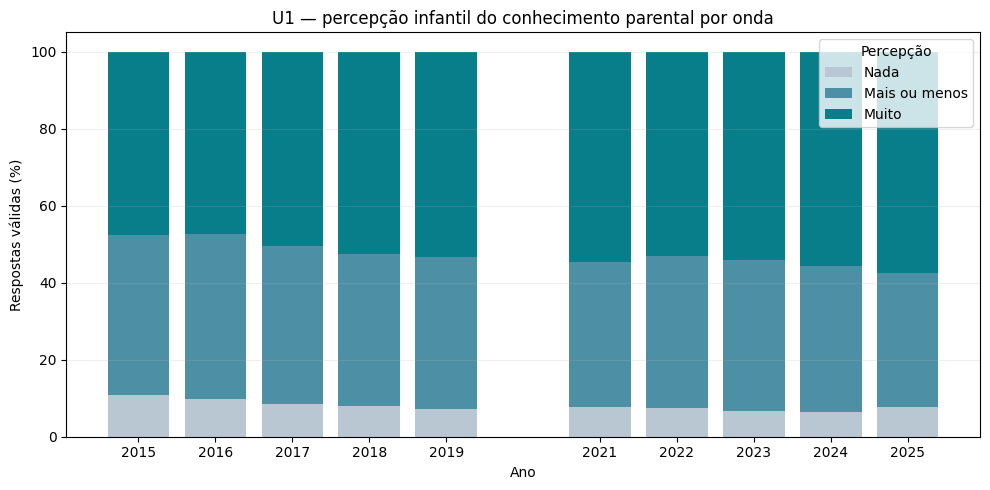

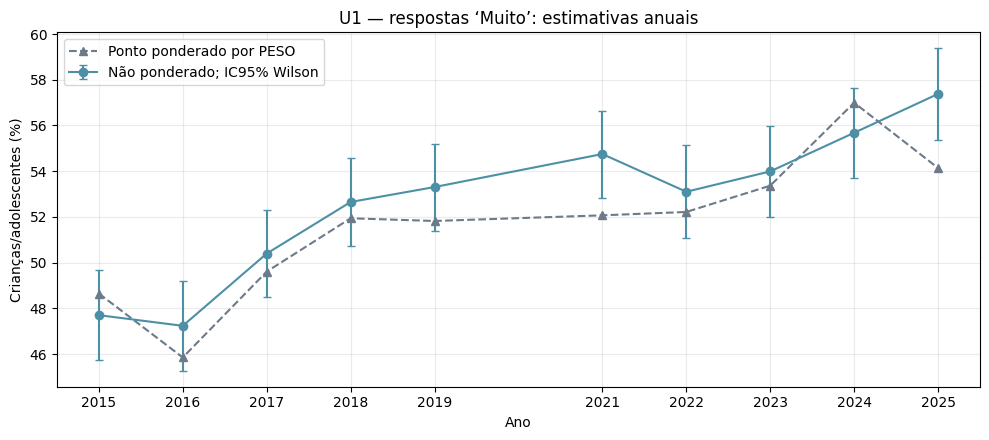

Descritivamente, ‘Muito’ foi 47.7% em 2015 e 57.4% em 2025. A inspeção gráfica não substitui o teste temporal.


In [4]:
def wilson(k,n):
    if n==0:return (np.nan,np.nan)
    z=stats.norm.ppf(.975);p=k/n;den=1+z*z/n;centro=(p+z*z/(2*n))/den;margem=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return centro-margem,centro+margem
def prop_peso(y,w):
    y=np.asarray(y,float);w=np.asarray(w,float);ok=np.isfinite(y)&np.isfinite(w)&(w>0)
    return float(np.average(y[ok],weights=w[ok])) if ok.any() else np.nan

rotulos_u1={1:"Muito",2:"Mais ou menos",3:"Nada"}
linhas_u1=[]
for ano,g in dados.groupby("ano"):
    s=g.conhecimento_ord.dropna()
    for cod,rot in [(3,"Muito"),(2,"Mais ou menos"),(1,"Nada")]:
        n=len(s);k=int(s.eq(cod).sum());lo,hi=wilson(k,n)
        linhas_u1.append({"ano":ano,"categoria":rot,"n":n,"proporção":k/n if n else np.nan,"IC95% inferior":lo,"IC95% superior":hi,
           "proporção ponderada":prop_peso(s.eq(cod),g.loc[s.index,"peso"])})
desc_u1=pd.DataFrame(linhas_u1)
display(desc_u1.pivot(index="ano",columns="categoria",values="proporção").round(3))

ordem=["Nada","Mais ou menos","Muito"];tab=desc_u1.pivot(index="ano",columns="categoria",values="proporção").reindex(columns=ordem).fillna(0)
fig,ax=plt.subplots(figsize=(10,5));base=np.zeros(len(tab))
cores=["#B8C7D1","#4D90A6","#087E8B"]
for cat,cor in zip(ordem,cores):
    ax.bar(tab.index,100*tab[cat],bottom=100*base,label=cat,color=cor);base+=tab[cat].to_numpy()
ax.set(title="U1 — percepção infantil do conhecimento parental por onda",xlabel="Ano",ylabel="Respostas válidas (%)",xticks=tab.index);ax.legend(title="Percepção");ax.grid(axis="y",alpha=.2);plt.tight_layout();plt.show()

u1_muito=desc_u1[desc_u1.categoria=="Muito"].sort_values("ano")
fig,ax=plt.subplots(figsize=(10,4.5))
ax.errorbar(u1_muito.ano,100*u1_muito.proporção,yerr=[100*(u1_muito.proporção-u1_muito["IC95% inferior"]),100*(u1_muito["IC95% superior"]-u1_muito.proporção)],marker="o",capsize=3,color=PALETA["conhecimento"],label="Não ponderado; IC95% Wilson")
ax.plot(u1_muito.ano,100*u1_muito["proporção ponderada"],marker="^",linestyle="--",color=PALETA["neutro"],label="Ponto ponderado por PESO")
ax.set(title="U1 — respostas ‘Muito’: estimativas anuais",xlabel="Ano",ylabel="Crianças/adolescentes (%)",xticks=u1_muito.ano);ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.show()
print(f"Descritivamente, ‘Muito’ foi {u1_muito.iloc[0].proporção:.1%} em 2015 e {u1_muito.iloc[-1].proporção:.1%} em 2025. A inspeção gráfica não substitui o teste temporal.")

### 2.2 Teste principal de tendência — regressão logística ordinal

**Por que este teste:** U1 tem três categorias ordenadas. A regressão logística ordinal de chances proporcionais aproveita essa ordem e testa se o deslocamento para categorias de maior conhecimento percebido se associa ao ano. Recodificamos “Nada” < “Mais ou menos” < “Muito”.

**Hipóteses explícitas:** H₀: β_ano = 0 (OR por ano = 1; sem deslocamento da distribuição ordinal). H₁: β_ano ≠ 0 (há tendência temporal; o sinal de β indica a direção). Reportamos coeficiente, OR anual, IC95%, estatística z e p-valor. A interpretação pressupõe chances proporcionais e independência entre respondentes; o ajuste não incorpora pesos/estratos/conglomerados. A pandemia e a lacuna de coleta em 2020 podem quebrar uma tendência linear; não interpolamos esse ano.

In [5]:
u1=dados[["ano","conhecimento_ord"]].dropna().copy();u1["ano_c"]=(u1.ano-2015).astype(float)
modelo_u1=OrderedModel(u1.conhecimento_ord,u1[["ano_c"]],distr="logit")
ajuste_u1=modelo_u1.fit(method="bfgs",disp=False)
beta=float(ajuste_u1.params["ano_c"]);se=float(ajuste_u1.bse["ano_c"]);z=beta/se;pval=2*stats.norm.sf(abs(z));ci_beta=(beta-1.96*se,beta+1.96*se)
resultado_u1=pd.DataFrame([{"teste":"Logístico ordinal de chances proporcionais","n":len(u1),"ondas":u1.ano.nunique(),"β ano":beta,"OR por ano":np.exp(beta),"IC95% OR inferior":np.exp(ci_beta[0]),"IC95% OR superior":np.exp(ci_beta[1]),"z":z,"gl":1,"p":pval}])
display(resultado_u1)
print("Interpretação:","a percepção deslocou-se para categorias mais altas ao longo das ondas" if beta>0 else "a percepção deslocou-se para categorias mais baixas ao longo das ondas",f"(OR={np.exp(beta):.3f}/ano; p={pval:.3g}).")

,teste,n,ondas,β ano,OR por ano,IC95% OR inferior,IC95% OR superior,z,gl,p
0,Logístico ordinal de chances proporcionais,24811,10,0.036145,1.036806,1.029156,1.044513,9.565921,1,1.112068e-21


Interpretação: a percepção deslocou-se para categorias mais altas ao longo das ondas (OR=1.037/ano; p=1.11e-21).


### 2.3 Sensibilidade com limiares binários

**Por que sensibilidades:** embora o modelo ordinal preserve U1, dois limiares são fáceis de comunicar: (a) “Muito” versus as demais respostas; (b) “Muito/Mais ou menos” versus “Nada”. Para cada limiar usamos GLM binomial com ano contínuo e erro-padrão robusto HC3. Os dois p-valores formam uma família e recebem ajuste de Holm. **Hipóteses em cada limiar:** H₀: β_ano = 0 (OR/ano = 1; proporção constante). H₁: β_ano ≠ 0 (proporção muda com o ano). Holm ajusta os dois p-valores. Essas análises não substituem o modelo ordinal nem corrigem o desenho complexo.

In [6]:
def tendencia_logistica(frame,col,nome):
    s=frame[["ano",col]].dropna().copy();s["ano_c"]=(s.ano-2015).astype(float);s["y"]=s[col].astype(int)
    fit=sm.GLM(s.y,sm.add_constant(s.ano_c),family=sm.families.Binomial()).fit(cov_type="HC3")
    b=float(fit.params["ano_c"]);lo,hi=fit.conf_int().loc["ano_c"]
    return {"desfecho":nome,"n":len(s),"ondas":s.ano.nunique(),"OR/ano":np.exp(b),"IC95% inferior":np.exp(lo),"IC95% superior":np.exp(hi),"Wald χ²":float(fit.tvalues["ano_c"]**2),"gl":1,"p":float(fit.pvalues["ano_c"])}

u1bin=dados[["ano","conhecimento_ord"]].dropna().copy()
u1bin["muito"]=u1bin.conhecimento_ord.eq(3).astype(int);u1bin["ao_menos_moderado"]=u1bin.conhecimento_ord.ge(2).astype(int)
sens_u1=pd.DataFrame([tendencia_logistica(u1bin,"muito","‘Muito’"),tendencia_logistica(u1bin,"ao_menos_moderado","‘Muito’ ou ‘Mais ou menos’")])
sens_u1["p Holm"]=multipletests(sens_u1.p,method="holm")[1]
display(sens_u1)

,desfecho,n,ondas,OR/ano,IC95% inferior,IC95% superior,Wald χ²,gl,p,p Holm
0,‘Muito’,24811,10,1.035421,1.027569,1.043333,80.315077,1,3.192239e-19,6.384479e-19
1,‘Muito’ ou ‘Mais ou menos’,24811,10,1.045136,1.030177,1.060312,36.024830,1,1.948191e-09,1.948191e-09


## 3. Medida 2 — conversa sobre a vida online autorrelatada pelo responsável

**Estimando:** proporção de respostas válidas em que o responsável relata alguma conversa sobre o que a criança faz na Internet. Nos anos antigos, o item é “sim/não”; em 2024, qualquer frequência de “Sempre” a “Quase nunca” conta como conversa, e “Nunca” conta como ausência. O item parental não aparece nos CSVs locais em 2018, 2021, 2023 ou 2025.

A série, portanto, contém seis ondas. Os gráficos mostram níveis, intervalos clássicos e estimativas pontuais ponderadas antes do modelo temporal.

### 3.1 Exploração gráfica do autorrelato parental

,ano,medida,n,proporção,IC95% inferior,IC95% superior,ponderada
0,2015,Responsável: alguma conversa,2409,0.7563,0.7388,0.7731,0.7479
1,2016,Responsável: alguma conversa,2425,0.7806,0.7637,0.7966,0.7721
2,2017,Responsável: alguma conversa,2614,0.8057,0.7900,0.8204,0.8150
3,2019,Responsável: alguma conversa,2676,0.8217,0.8068,0.8358,0.8214
4,2022,Responsável: alguma conversa,2366,0.8250,0.8092,0.8398,0.8644
5,2024,Responsável: alguma conversa,2467,0.8857,0.8725,0.8977,0.9032


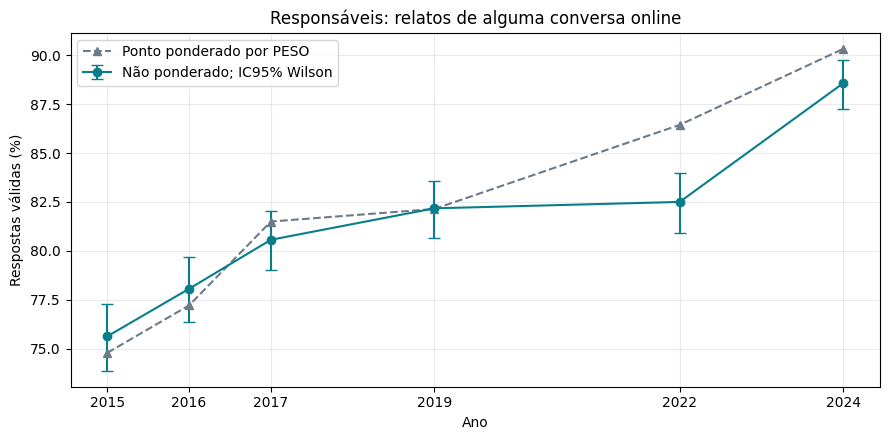

A linha tem lacunas em ondas sem variável parental nos microdados locais; essas lacunas não são zeros nem respostas negativas.


In [7]:
def tabela_binaria(col,rotulo):
    linhas=[]
    for ano,g in dados.groupby("ano"):
        s=g[col].dropna()
        if not len(s):continue
        y=s.eq(1).astype(int);lo,hi=wilson(int(y.sum()),len(y))
        linhas.append({"ano":ano,"medida":rotulo,"n":len(y),"proporção":y.mean(),"IC95% inferior":lo,"IC95% superior":hi,"ponderada":prop_peso(y,g.loc[s.index,"peso"])})
    return pd.DataFrame(linhas)
desc_resp=tabela_binaria("responsavel_conversa","Responsável: alguma conversa")
display(desc_resp.round(4))
fig,ax=plt.subplots(figsize=(9,4.5));s=desc_resp.sort_values("ano")
ax.errorbar(s.ano,100*s.proporção,yerr=[100*(s.proporção-s["IC95% inferior"]),100*(s["IC95% superior"]-s.proporção)],marker="o",capsize=4,color=PALETA["responsavel"],label="Não ponderado; IC95% Wilson")
ax.plot(s.ano,100*s.ponderada,marker="^",linestyle="--",color=PALETA["neutro"],label="Ponto ponderado por PESO")
ax.set(title="Responsáveis: relatos de alguma conversa online",xlabel="Ano",ylabel="Respostas válidas (%)",xticks=s.ano);ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.show()
print("A linha tem lacunas em ondas sem variável parental nos microdados locais; essas lacunas não são zeros nem respostas negativas.")

### 3.2 Teste de tendência no autorrelato parental

**Teste:** regressão logística binomial com resposta 1 = alguma conversa e 0 = nunca/não; preditor contínuo = ano. O teste de Wald avalia β_ano = 0 e produz OR por ano e IC95% robusto HC3. Como o desfecho já está harmonizado em duas categorias, não usamos Wilcoxon.

**Hipóteses explícitas:** H₀: β_ano = 0 (OR/ano = 1; chances de relato constantes nas ondas observadas). H₁: β_ano ≠ 0 (há tendência temporal). **Limites:** o modelo tem seis ondas observadas (2015, 2016, 2017, 2019, 2022 e 2024), com intervalos desiguais e sem coleta em 2020. O coeficiente resume uma tendência linear não ponderada; mudança de questionário, período pandêmico e plano amostral podem afetar sua interpretação.

In [8]:
resultado_resp=tendencia_logistica(dados,"responsavel_conversa","Responsável: alguma conversa")
res_resp=pd.DataFrame([resultado_resp]);display(res_resp)
print(f"OR anual={resultado_resp['OR/ano']:.3f} (IC95% {resultado_resp['IC95% inferior']:.3f}–{resultado_resp['IC95% superior']:.3f}); p={resultado_resp['p']:.3g}. Interpretação restrita às ondas com relato parental disponível.")

,desfecho,n,ondas,OR/ano,IC95% inferior,IC95% superior,Wald χ²,gl,p
0,Responsável: alguma conversa,14957,6,1.084324,1.069813,1.099032,138.698684,1,5.126143e-32


OR anual=1.084 (IC95% 1.070–1.099); p=5.13e-32. Interpretação restrita às ondas com relato parental disponível.


## 4. Medida 3 — conversa sobre a vida online percebida pela criança

**Estimando:** proporção de crianças/adolescentes que percebe alguma conversa dos pais/responsáveis sobre o que faz na Internet. U4_G é binária nas ondas antigas; U6_G é escala de frequência nas ondas recentes em que o item se refere a pais/responsáveis. U6_G de anos anteriores com referência a professores não entra nesta medida. A dicotomização recente “qualquer conversa versus nunca” perde informação sobre intensidade.

### 4.1 Exploração gráfica da percepção infantil de conversa parental

,ano,medida,n,proporção,IC95% inferior,IC95% superior,ponderada
0,2015,Criança: percebe alguma conversa,2456,0.6914,0.6728,0.7093,0.6897
1,2016,Criança: percebe alguma conversa,2482,0.7188,0.7008,0.7361,0.7114
2,2017,Criança: percebe alguma conversa,2648,0.7292,0.7120,0.7458,0.7159
3,2018,Criança: percebe alguma conversa,2591,0.7047,0.6869,0.7220,0.6805
4,2019,Criança: percebe alguma conversa,2653,0.7444,0.7275,0.7607,0.7393
5,2021,Criança: percebe alguma conversa,2638,0.6687,0.6505,0.6864,0.6932
6,2022,Criança: percebe alguma conversa,2321,0.6894,0.6702,0.7079,0.7143
7,2023,Criança: percebe alguma conversa,2373,0.6705,0.6513,0.6891,0.6905
8,2024,Criança: percebe alguma conversa,2410,0.7975,0.7810,0.8131,0.7591
9,2025,Criança: percebe alguma conversa,2346,0.7745,0.7572,0.7910,0.7547


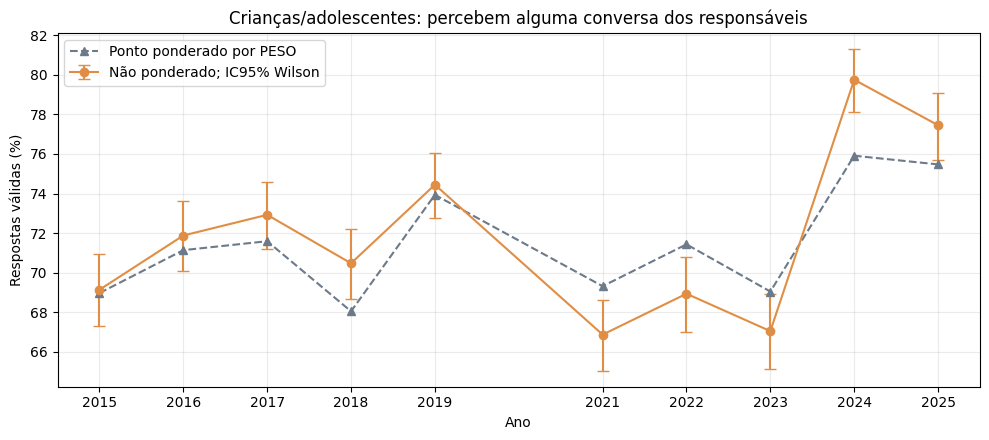

Proporção não ponderada: 69.1% em 2015 e 77.5% em 2025.


In [9]:
desc_cri=tabela_binaria("crianca_conversa","Criança: percebe alguma conversa")
display(desc_cri.round(4))
fig,ax=plt.subplots(figsize=(10,4.5));s=desc_cri.sort_values("ano")
ax.errorbar(s.ano,100*s.proporção,yerr=[100*(s.proporção-s["IC95% inferior"]),100*(s["IC95% superior"]-s.proporção)],marker="o",capsize=4,color=PALETA["crianca"],label="Não ponderado; IC95% Wilson")
ax.plot(s.ano,100*s.ponderada,marker="^",linestyle="--",color=PALETA["neutro"],label="Ponto ponderado por PESO")
ax.set(title="Crianças/adolescentes: percebem alguma conversa dos responsáveis",xlabel="Ano",ylabel="Respostas válidas (%)",xticks=s.ano);ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.show()
print(f"Proporção não ponderada: {s.iloc[0].proporção:.1%} em {int(s.iloc[0].ano)} e {s.iloc[-1].proporção:.1%} em {int(s.iloc[-1].ano)}.")

### 4.2 Teste temporal da percepção infantil de conversa

**Teste:** GLM logístico binomial com ano contínuo. O β_ano testa tendência linear nas chances de a criança perceber alguma conversa; reportamos OR/ano, IC95%, Wald χ² com 1 grau de liberdade e p. O p-valor será ajustado por Holm junto com o teste temporal da medida parental (duas perspectivas, uma família).

**Hipóteses explícitas:** H₀: β_ano = 0 (OR/ano = 1; chances de perceber conversa constantes). H₁: β_ano ≠ 0 (há tendência). O teste é bilateral e seu p-valor recebe ajuste Holm junto ao teste da seção 3. Este teste avalia uma proporção binária harmonizada, não a intensidade da conversa. A análise não ponderada usa HC3 e presume independência entre crianças/domicílios; bandas dos gráficos são Wilson clássicos, não intervalos por desenho amostral.

In [10]:
resultado_cri=tendencia_logistica(dados,"crianca_conversa","Criança: percebe alguma conversa")
trend_conversa=pd.DataFrame([resultado_resp,resultado_cri])
trend_conversa["p Holm"]=multipletests(trend_conversa.p,method="holm")[1]
display(trend_conversa)
for _,r in trend_conversa.iterrows():
    sentido="aumentam" if r["OR/ano"]>1 else "diminuem"
    display(Markdown(f"**Leitura — {r['desfecho']}:** as chances {sentido} por ano (OR={r['OR/ano']:.3f}; IC95% {r['IC95% inferior']:.3f}–{r['IC95% superior']:.3f}; p Holm={r['p Holm']:.3g})."))

,desfecho,n,ondas,OR/ano,IC95% inferior,IC95% superior,Wald χ²,gl,p,p Holm
0,Responsável: alguma conversa,14957,6,1.084324,1.069813,1.099032,138.698684,1,5.126143e-32,1.025229e-31
1,Criança: percebe alguma conversa,24918,10,1.019726,1.011295,1.028228,21.264380,1,4.000975e-06,4.000975e-06


**Leitura — Responsável: alguma conversa:** as chances aumentam por ano (OR=1.084; IC95% 1.070–1.099; p Holm=1.03e-31).

**Leitura — Criança: percebe alguma conversa:** as chances aumentam por ano (OR=1.020; IC95% 1.011–1.028; p Holm=4e-06).

### 4.3 Exploração do pareamento e da direção das discordâncias

Antes de testar diferenças entre informantes, descrevemos a matriz de respostas na mesma díade. “Responsável sim/criança não” e “responsável não/criança sim” mostram a direção da discordância. A diferença marginal não é calculada como se os grupos fossem independentes; a análise seguinte manterá o pareamento.

,ano,n díades,concordam sim,concordam não,responsável sim/criança não,responsável não/criança sim
0,2015,2324,1391,317,370,246
1,2016,2335,1442,262,384,247
2,2017,2519,1601,240,428,250
3,2019,2581,1680,227,437,237
4,2022,2264,1402,231,466,165
5,2024,2332,1720,113,351,148


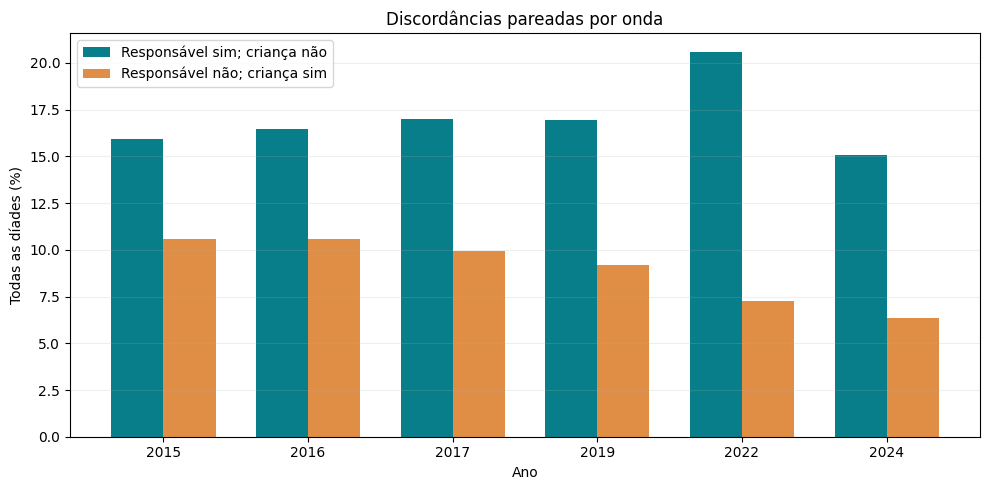

In [11]:
pares=dados.dropna(subset=["responsavel_conversa","crianca_conversa"]).copy()
linhas_dir=[]
for ano,g in pares.groupby("ano"):
    a=g.responsavel_conversa.astype(int);b=g.crianca_conversa.astype(int);n=len(g)
    linhas_dir.append({"ano":ano,"n díades":n,"concordam sim":int(((a==1)&(b==1)).sum()),"concordam não":int(((a==0)&(b==0)).sum()),
      "responsável sim/criança não":int(((a==1)&(b==0)).sum()),"responsável não/criança sim":int(((a==0)&(b==1)).sum())})
direcoes=pd.DataFrame(linhas_dir);display(direcoes)
fig,ax=plt.subplots(figsize=(10,5));x=np.arange(len(direcoes));w=.36
ax.bar(x-w/2,100*direcoes["responsável sim/criança não"]/direcoes["n díades"],w,label="Responsável sim; criança não",color=PALETA["responsavel"])
ax.bar(x+w/2,100*direcoes["responsável não/criança sim"]/direcoes["n díades"],w,label="Responsável não; criança sim",color=PALETA["crianca"])
ax.set(title="Discordâncias pareadas por onda",xlabel="Ano",ylabel="Todas as díades (%)",xticks=x,xticklabels=direcoes.ano);ax.grid(axis="y",alpha=.2);ax.legend();plt.tight_layout();plt.show()

### 4.4 Teste pareado por onda: McNemar, diferença, κ e AC1

**McNemar exato:** para desfecho binário pareado, testa se as duas discordâncias são igualmente frequentes. O teste binomial exato usa apenas os pares discordantes; seu p-valor responde se as margens diferem. **Hipóteses explícitas por ano:** H₀: p(responsável=sim, criança=não) = p(responsável=não, criança=sim), equivalente à igualdade das margens pareadas. H₁: essas probabilidades diferem. O teste é bilateral; Holm corrige a família das seis ondas pareáveis.

**Magnitude:** diferença pareada (proporção do responsável menos proporção percebida pela criança) e IC95% por bootstrap de díades. κ de Cohen e AC1 de Gwet medem concordância além do acaso; ICs também são bootstrap por díade. As estimativas ponderadas são exibidas como pontos descritivos; seus erros-padrão não são calculados sem parâmetros confirmados das réplicas. O bootstrap clássico não reproduz o desenho complexo.

In [12]:
def kappa_ac1(a,b):
    a=np.asarray(a,int);b=np.asarray(b,int);tab=np.zeros((2,2),float)
    for x,y in zip(a,b):tab[x,y]+=1
    po=np.trace(tab)/len(a);pa=tab[1,:].sum()/len(a);pb=tab[:,1].sum()/len(a)
    pe=pa*pb+(1-pa)*(1-pb);k=(po-pe)/(1-pe) if pe<1 else np.nan
    pbar=(pa+pb)/2;pe1=2*pbar*(1-pbar);ac=(po-pe1)/(1-pe1) if pe1<1 else np.nan
    return k,ac
def boot_pareado(a,b,seed):
    a=np.asarray(a,int);b=np.asarray(b,int);n=len(a);rng=np.random.default_rng(seed)
    dif=[];ks=[];acs=[]
    for ix in rng.integers(0,n,size=(B_BOOT,n)):
        dif.append((a[ix]-b[ix]).mean());k,ac=kappa_ac1(a[ix],b[ix]);ks.append(k);acs.append(ac)
    return np.quantile(dif,[.025,.975]),np.nanquantile(ks,[.025,.975]),np.nanquantile(acs,[.025,.975])

linhas_testes=[]
for ano,g in pares.groupby("ano"):
    a=g.responsavel_conversa.astype(int).to_numpy();b=g.crianca_conversa.astype(int).to_numpy()
    b10=int(((a==1)&(b==0)).sum());c01=int(((a==0)&(b==1)).sum());nd=b10+c01
    p_exact=stats.binomtest(b10,nd,p=.5).pvalue if nd else 1.0
    ci_dif,ci_k,ci_ac=boot_pareado(a,b,SEED+int(ano));k,ac=kappa_ac1(a,b)
    peso=g.peso.to_numpy(float);ok=np.isfinite(peso)&(peso>0)
    diff_peso=float(np.average(a[ok]-b[ok],weights=peso[ok])) if ok.any() else np.nan
    linhas_testes.append({"ano":ano,"n díades":len(g),"discordância resp+/criança−":b10,"discordância resp−/criança+":c01,
      "p McNemar exato":p_exact,"diferença pareada":(a-b).mean(),"IC95% dif inf":ci_dif[0],"IC95% dif sup":ci_dif[1],"diferença com PESO":diff_peso,
      "κ Cohen":k,"IC95% κ inf":ci_k[0],"IC95% κ sup":ci_k[1],"AC1 Gwet":ac,"IC95% AC1 inf":ci_ac[0],"IC95% AC1 sup":ci_ac[1]})
resultados_pareados=pd.DataFrame(linhas_testes)
resultados_pareados["p Holm"]=multipletests(resultados_pareados["p McNemar exato"],method="holm")[1]
display(resultados_pareados)
print(f"Em {(resultados_pareados['p Holm']<.05).sum()} de {len(resultados_pareados)} ondas, as margens diferem após ajuste de Holm.")

,ano,n díades,discordância resp+/criança−,discordância resp−/criança+,p McNemar exato,diferença pareada,IC95% dif inf,IC95% dif sup,diferença com PESO,κ Cohen,IC95% κ inf,IC95% κ sup,AC1 Gwet,IC95% AC1 inf,IC95% AC1 sup,p Holm
0,2015,2324,370,246,6.632084e-07,0.053356,0.031831,0.073580,0.050302,0.328348,0.284407,0.366917,0.563172,0.527297,0.594646,6.632084e-07
1,2016,2335,384,247,5.489919e-08,0.058672,0.038544,0.079229,0.060260,0.277503,0.235268,0.319367,0.569477,0.536555,0.602858,1.097984e-07
2,2017,2519,428,250,8.122096e-12,0.070663,0.050020,0.089321,0.092312,0.245089,0.203473,0.287228,0.583326,0.553264,0.613080,2.436629e-11
3,2019,2581,437,237,1.147621e-14,0.077489,0.058485,0.097249,0.081648,0.242065,0.197474,0.286172,0.603411,0.573572,0.636055,4.590482e-14
4,2022,2264,466,165,3.655589e-34,0.132951,0.110855,0.153721,0.148756,0.256924,0.216422,0.300487,0.560228,0.526085,0.595447,2.193354e-33
5,2024,2332,351,148,4.617338e-20,0.087050,0.068611,0.105489,0.141718,0.196635,0.146905,0.245282,0.709833,0.679264,0.736856,2.308669e-19


Em 6 de 6 ondas, as margens diferem após ajuste de Holm.


### 4.5 Sensibilidade ordinal específica de 2024

A dicotomização facilita comparar ondas, mas perde a ordenação 1–5 de 2024. Como sensibilidade local, repetimos o Wilcoxon de postos sinalizados da referência em E9_G × U6_G, após inverter a escala (6 − código). **Hipóteses:** H₀: a pseudomediana das diferenças pareadas é zero; H₁: a pseudomediana é diferente de zero. O p-valor bilateral de Wilcoxon não testa toda forma de diferença sem pressupostos: a interpretação como deslocamento exige diferenças aproximadamente simétricas. O teste ordinal não é diretamente comparável às ondas antigas binárias. Reportamos W, z aproximado, p, bisserial de postos e IC95% bootstrap.

In [13]:
g24=dados[(dados.ano==2024)&dados.resp_raw.isin([1,2,3,4,5])&dados.cri_raw.isin([1,2,3,4,5])].copy()
x=6-g24.resp_raw.to_numpy();y=6-g24.cri_raw.to_numpy();dif=x-y
wil=stats.wilcoxon(x,y,zero_method="wilcox",alternative="two-sided",method="approx")
def r_rb(v):
    v=np.asarray(v);v=v[v!=0]
    if len(v)==0:return np.nan
    ranks=stats.rankdata(np.abs(v));return (ranks[v>0].sum()-ranks[v<0].sum())/ranks.sum()
r=r_rb(dif);rng=np.random.default_rng(SEED+2024);rb_boot=[r_rb(dif[ix]) for ix in rng.integers(0,len(dif),size=(B_BOOT,len(dif)))];ci_rb=np.quantile(rb_boot,[.025,.975])
print(f"2024 ordinal: n={len(dif)}, W={wil.statistic:.1f}, z={wil.zstatistic:.2f}, p={wil.pvalue:.3g}, r_rb={r:.3f}, IC95% bootstrap {ci_rb[0]:.3f}–{ci_rb[1]:.3f}.")

2024 ordinal: n=2332, W=228424.5, z=-18.47, p=3.29e-76, r_rb=0.557, IC95% bootstrap 0.504–0.602.


### 4.6 Exploração e tendência temporal do gap

O gap tem duas faces: (a) **discordância total**, qualquer diferença entre os dois relatos; (b) **gap líquido**, proporção que relata conversa pelo responsável menos a proporção percebida pela criança. Uma pode cair enquanto a outra sobe se a direção das discordâncias se tornar mais assimétrica. Primeiro plotamos ambas; em seguida testamos cada estimando separadamente.

,ano,n,gap_liquido,discordancia
0,2015,2324,0.053356,0.26506
1,2016,2335,0.058672,0.270236
2,2017,2519,0.070663,0.269154
3,2019,2581,0.077489,0.261139
4,2022,2264,0.132951,0.27871
5,2024,2332,0.087050,0.213979


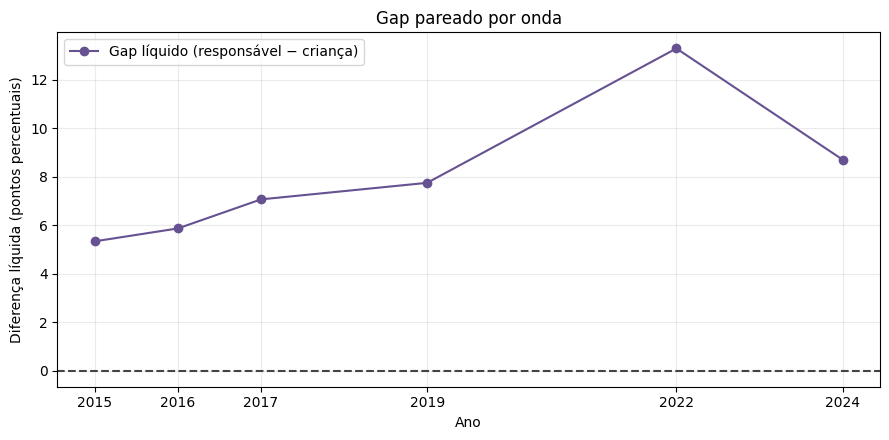

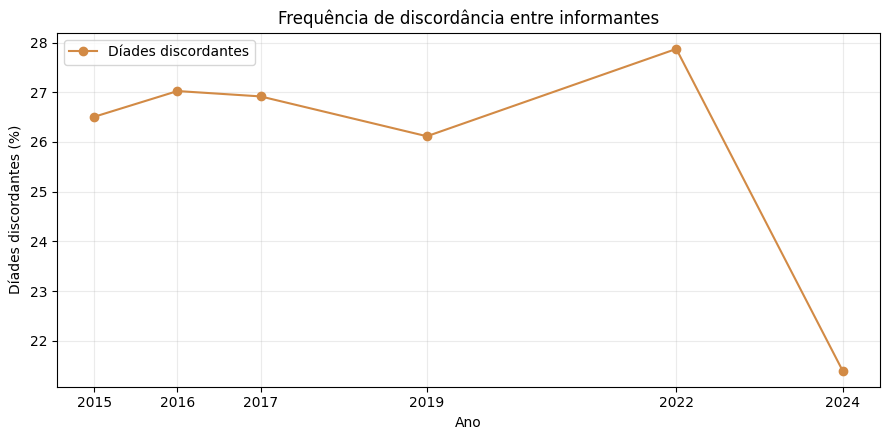

In [14]:
gap_anual=pares.groupby("ano").agg(n=("gap","size"),gap_liquido=("gap","mean"),discordancia=("discordancia","mean")).reset_index()
display(gap_anual)
fig,ax=plt.subplots(figsize=(9,4.5));ax.plot(gap_anual.ano,100*gap_anual.gap_liquido,marker="o",color=PALETA["gap"],label="Gap líquido (responsável − criança)")
ax.axhline(0,color="#444",linestyle="--");ax.set(title="Gap pareado por onda",xlabel="Ano",ylabel="Diferença líquida (pontos percentuais)",xticks=gap_anual.ano);ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,4.5));ax.plot(gap_anual.ano,100*gap_anual.discordancia,marker="o",color="#D28A45",label="Díades discordantes")
ax.set(title="Frequência de discordância entre informantes",xlabel="Ano",ylabel="Díades discordantes (%)",xticks=gap_anual.ano);ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.show()

### 4.7 Testes de tendência do gap

**Discordância total:** regressão logística binomial da ocorrência de discordância pelo ano; β_ano = 0 significa chances constantes.

**Gap líquido:** regressão linear do contraste pareado −1/0/+1 pelo ano com erro HC3; β é a mudança média anual em pontos da escala binária. O sinal indica se aumenta a predominância do relato parental ou infantil. **Hipóteses explícitas:** para discordância, H₀: β_ano = 0 (OR/ano = 1; chance de discordar constante); H₁: β_ano ≠ 0. Para gap líquido, H₀: β_ano = 0 (diferença líquida média sem tendência); H₁: β_ano ≠ 0. São testes bilaterais; Holm ajusta os dois p-valores do gap. Ambos são não ponderados e descrevem ondas independentes, não mudanças nas mesmas famílias.

In [15]:
trend_gap=[]
r_disc=tendencia_logistica(pares,"discordancia","Discordância total")
trend_gap.append({"desfecho":r_disc["desfecho"],"n":r_disc["n"],"ondas":r_disc["ondas"],"estimativa/ano (OR ou β)":r_disc["OR/ano"],"IC95% inferior":r_disc["IC95% inferior"],"IC95% superior":r_disc["IC95% superior"],"estatística":r_disc["Wald χ²"],"gl":1,"p":r_disc["p"]})
s=pares[["ano","gap"]].dropna().copy();s["ano_c"]=s.ano-2015
fit_gap=sm.OLS(s.gap,sm.add_constant(s.ano_c)).fit(cov_type="HC3");b=float(fit_gap.params["ano_c"]);lo,hi=fit_gap.conf_int().loc["ano_c"]
trend_gap.append({"desfecho":"Gap líquido (β OLS por ano)","n":len(s),"ondas":s.ano.nunique(),"estimativa/ano (OR ou β)":b,"IC95% inferior":lo,"IC95% superior":hi,"estatística":float(fit_gap.tvalues["ano_c"]**2),"gl":1,"p":float(fit_gap.pvalues["ano_c"])})
resultados_gap=pd.DataFrame(trend_gap);resultados_gap["p Holm"]=multipletests(resultados_gap.p,method="holm")[1]
display(resultados_gap)
print(f"Leitura: OR/ano da discordância={r_disc['OR/ano']:.3f}; β do gap líquido={b:.4f} (isto é, {100*b:.2f} ponto percentual por ano). São aspectos diferentes da discrepância.")

,desfecho,n,ondas,estimativa/ano (OR ou β),IC95% inferior,IC95% superior,estatística,gl,p,p Holm
0,Discordância total,14355,6,0.979620,0.968276,0.991096,12.006349,1,0.000530,0.000530
1,Gap líquido (β OLS por ano),14355,6,0.006045,0.003540,0.008551,22.366524,1,0.000002,0.000005


Leitura: OR/ano da discordância=0.980; β do gap líquido=0.0060 (isto é, 0.60 ponto percentual por ano). São aspectos diferentes da discrepância.


## 5. Síntese, validade e limites

1. **U1** mede conhecimento parental percebido pela criança; não é a mesma coisa que uma prática de conversa. A regressão ordinal respeita a ordem das três categorias.
2. **Autorrelato parental** de conversa está disponível em seis ondas locais. A linha temporal é interrompida nos anos em que o campo não está no CSV.
3. **Percepção infantil de conversa** está disponível em dez ondas; harmonizar binário e frequência em “qualquer conversa versus nunca” elimina diferenças de intensidade.
4. **Gap:** o resultado do teste de discordância total deve ser lido junto com o gap líquido, pois medem frequência e direção, respectivamente.
5. ICs de Wilson e bootstrap são clássicos. PESO foi usado para estimativas pontuais. Os microdados têm 200 réplicas em algumas ondas recentes; sem confirmar escala, rscales, centragem e graus de liberdade, não calculamos inferência por desenho.
6. Os modelos temporais usam ano como preditor em cortes transversais repetidos e não ajustam mudança de modo de coleta, contexto pandêmico, covariáveis ou desenho amostral. Não implicam causalidade nem mudança individual.
7. A TIC Kids Online não foi realizada em 2020; ver [relatório oficial da edição de 2020](https://cetic.br/media/docs/publicacoes/2/20211125083634/tic_kids_online_2020_livro_eletronico.pdf).